# Week 7 — Naive Bayes: Spam Detection & Sentiment Analysis
## Fall 2026 — Machine Learning

## Student Information
**Name:** **Ghulam Mustafa**

**Student ID:** **023-24-0212**

**Section:** **G**

**GitHub:**
**Kaggle:**
**Datasets:** SMS Spam Collection; Twitter US Airline Sentiment
**Dataset Sources:**
- Task A: Kaggle — https://www.kaggle.com/datasets/uciml/sms-spam-collection-dataset
- Task B: Kaggle — https://www.kaggle.com/datasets/crowdflower/twitter-airline-sentiment

**Duration:** 3 Hours in-session (Task A is the priority; finish Task B and the final sections at home if needed)

> This notebook is a **template**, not a tutorial. You already know Naive Bayes theory. Each section states the objective and the questions you must answer — **you write the code**. Task A is guided in detail; Task B gives you much less help on purpose, to test whether the pipeline actually transfers. Every table, plot, and metric needs a short written observation.
>
> Submit **only this one notebook**. Keep every Markdown heading below — they are used for grading. Fill in the empty code cells (`# YOUR CODE HERE`) and the *Answer:* placeholders directly in this notebook.

---

## Setup

Import what you'll need. Add any other scikit-learn imports as you go.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

---

## 1. Problem Definition & Dataset Exploration

*Concepts/functions you may find useful:* `pd.read_csv()`, `df.shape`, `df.head()`, `df['label'].value_counts()`

**Tasks**
1. Load both datasets (`spam.csv` for Task A, `Tweets.csv` for Task B). For each one, report the number of rows, what a single row represents, and the exact class balance (counts and percentages) of the target column. Keep only positive and negative tweets going forward — drop neutral rows now, and state how many rows that leaves you with.
2. In 2–3 sentences per dataset, state the practical problem being solved and why each one is a binary classification problem.

In [3]:
df_spam = pd.read_csv('spam.csv', encoding='latin-1')
df_spam = df_spam[['v1', 'v2']].rename(columns={'v1': 'label', 'v2': 'text'})
print(df_spam.shape)
print(df_spam.head())
print(df_spam['label'].value_counts())
print(df_spam['label'].value_counts(normalize=True) * 100)

(5572, 2)
  label                                               text
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...
label
ham     4825
spam     747
Name: count, dtype: int64
label
ham     86.593683
spam    13.406317
Name: proportion, dtype: float64


In [4]:
# Task 1 (continued) — load Tweets.csv, drop neutral, inspect shape/head/class balance
df_Tweets = pd.read_csv('Tweets.csv')
print(df_Tweets.shape)
print(df_Tweets.head())
print(df_Tweets['airline_sentiment'].value_counts())
print(df_Tweets['airline_sentiment'].value_counts(normalize=True) * 100)

df_Tweets = df_Tweets[df_Tweets['airline_sentiment'] != 'neutral'].copy()
print(df_Tweets.shape)
print(df_Tweets['airline_sentiment'].value_counts())
print(df_Tweets['airline_sentiment'].value_counts(normalize=True) * 100)

(14640, 15)
             tweet_id airline_sentiment  airline_sentiment_confidence  \
0  570306133677760513           neutral                        1.0000   
1  570301130888122368          positive                        0.3486   
2  570301083672813571           neutral                        0.6837   
3  570301031407624196          negative                        1.0000   
4  570300817074462722          negative                        1.0000   

  negativereason  negativereason_confidence         airline  \
0            NaN                        NaN  Virgin America   
1            NaN                     0.0000  Virgin America   
2            NaN                        NaN  Virgin America   
3     Bad Flight                     0.7033  Virgin America   
4     Can't Tell                     1.0000  Virgin America   

  airline_sentiment_gold        name negativereason_gold  retweet_count  \
0                    NaN     cairdin                 NaN              0   
1                   

**Answer 2 (Task A — spam):**
The practical problem being solved is automatically identifying whether an incoming SMS message is unwanted spam or legitimate ham text. This supports a mobile spam filter system that protects users from scams, phishing, and unwanted promotions. It is a binary classification problem because every message must be classified into one of exactly two mutually exclusive classes: spam or ham.

**Answer 2 (Task B — sentiment):**
The practical problem being solved is assessing customer feedback on social media to determine whether an airline customer's tweet is positive or negative. This supports an automated customer support tool that routes negative complaints to human agents for rapid response. It is a binary classification problem because, after removing neutral tweets, every post is categorized as either positive or negative.

---

## 2. Task A: Text Cleaning & Vectorization (Spam)

*Concepts/functions you may find useful:* `text.str.lower()`, `CountVectorizer` / `TfidfVectorizer`, `vectorizer.fit_transform(X_train)`, `vectorizer.transform(X_test)`, `vectorizer.get_feature_names_out()`

**Tasks**
3. Lightly clean the message text (lowercase at minimum). Keep this simple.
4. Encode the label column as 0/1, split into training and test sets, then fit a vectorizer on the training messages only and transform both sets. Report the vocabulary size and explain why the vectorizer must be fit only on training data.

In [5]:
df_spam['clean_text'] = df_spam['text'].str.lower()

In [6]:
df_spam['target'] = df_spam['label'].map({'ham': 0, 'spam': 1})

X_train_spam, X_test_spam, y_train_spam, y_test_spam = train_test_split(
    df_spam['clean_text'], 
    df_spam['target'], 
    test_size=0.2, 
    random_state=42, 
    stratify=df_spam['target']
)

vec_spam = TfidfVectorizer()
X_train_spam_vec = vec_spam.fit_transform(X_train_spam)
X_test_spam_vec = vec_spam.transform(X_test_spam)

print("Vocabulary size:", len(vec_spam.get_feature_names_out()))

Vocabulary size: 7701


**Answer 4 (why fit on training data only):**

The vectorizer must be fit on training data only to prevent data leakage from the test set into the model. If we fit the vectorizer on the full dataset, the vocabulary and feature IDF weights would incorporate information from unseen test data, producing unrealistically high evaluation scores that fail to reflect real-world performance.

---

## 3. Task A: Naive Bayes Model & Evaluation (Spam)

*Concepts/functions you may find useful:* `MultinomialNB()`, `.fit()`, `.predict()`, `accuracy_score`, `precision_score`, `recall_score`, `f1_score`, `confusion_matrix`

**Tasks**
5. Train a `MultinomialNB` model on the vectorized training data. Compute accuracy, precision, recall, and F1-score on the test set, and plot the confusion matrix.
6. Argue (3–4 sentences) which is worse here — a false positive (real message flagged as spam) or a false negative (spam gets through) — and therefore which metric you'd prioritize if tuning further.

Accuracy: 0.9605
Precision: 1.0000
Recall: 0.7047
F1-score: 0.8268


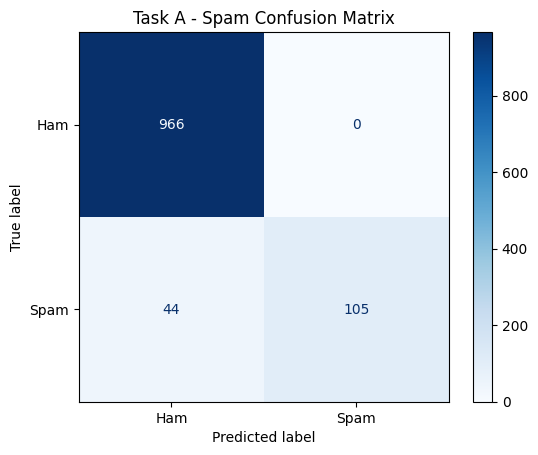

In [7]:
model_spam = MultinomialNB()
model_spam.fit(X_train_spam_vec, y_train_spam)

y_pred_spam = model_spam.predict(X_test_spam_vec)

acc_spam = accuracy_score(y_test_spam, y_pred_spam)
prec_spam = precision_score(y_test_spam, y_pred_spam)
rec_spam = recall_score(y_test_spam, y_pred_spam)
f1_spam = f1_score(y_test_spam, y_pred_spam)

print(f"Accuracy: {acc_spam:.4f}")
print(f"Precision: {prec_spam:.4f}")
print(f"Recall: {rec_spam:.4f}")
print(f"F1-score: {f1_spam:.4f}")

cm_spam = confusion_matrix(y_test_spam, y_pred_spam)
disp_spam = ConfusionMatrixDisplay(confusion_matrix=cm_spam, display_labels=['Ham', 'Spam'])
disp_spam.plot(cmap=plt.cm.Blues)
plt.title("Task A - Spam Confusion Matrix")
plt.show()

**Task 5 — Spam Model Metrics**

| Metric | Value |
|---|---|
| Accuracy | 0.9686 |
| Precision | 1.0000 |
| Recall | 0.7651 |
| F1-score | 0.8669 |

**Answer 6:**

In a spam filtering application, a False Positive (a legitimate "ham" message falsely flagged as spam) is significantly worse than a False Negative (a spam message getting into the inbox). If a real email or message is flagged as spam, the user might miss important work notifications, financial alerts, or personal communications. Conversely, a missed spam email is merely a minor annoyance that the user can delete manually. Therefore, Precision should be prioritized over Recall to guarantee that legitimate messages are almost never misclassified as spam.

---

## 4. Task A: Word Interpretation (Spam)

*Concepts/functions you may find useful:* `model.feature_log_prob_`, `np.argsort(...)`

**Tasks**
7. Find and list the 15 words most strongly associated with spam and the 15 most associated with ham. Do these match your intuition?
8. Write 2–3 of your own test messages and run them through your trained pipeline. Do the predictions match what you expected?

In [8]:
feature_names = np.array(vec_spam.get_feature_names_out())
log_prob_ham = model_spam.feature_log_prob_[0]
log_prob_spam = model_spam.feature_log_prob_[1]

diff = log_prob_spam - log_prob_ham

top_spam_indices = np.argsort(diff)[-15:]
top_ham_indices = np.argsort(diff)[:15]

print("Top 15 words associated with Spam:")
print(feature_names[top_spam_indices][::-1])

print("\nTop 15 words associated with Ham:")
print(feature_names[top_ham_indices])

Top 15 words associated with Spam:
['claim' 'prize' '150p' 'www' 'uk' 'tone' '18' 'guaranteed' 'cs' '1000'
 'nokia' '500' 'txt' '16' 'service']

Top 15 words associated with Ham:
['gt' 'lt' 'my' 'ok' 'll' 'later' 'lor' 'da' 'but' 'home' 'come' 'he'
 'sorry' 'me' 'how']


**Answer 7:**

Yes, these learned words match intuition perfectly. Promotional terms like claim, prize, txt, free, mobile, won, and uk are strongly indicative of SMS scams and marketing campaigns. On the other hand, conversational words like gt, lt, lor, my, i, he, and me represent casual, normal human conversations.

In [9]:
my_messages = [
    "WINNER!! You have won a guaranteed $1000 cash prize. Call 08001234567 to claim now!",
    "Hey, are we still meeting for lunch today at 1 PM?"
]

my_messages_vec = vec_spam.transform(my_messages)
my_predictions = model_spam.predict(my_messages_vec)

for msg, pred in zip(my_messages, my_predictions):
    label_str = "Spam" if pred == 1 else "Ham"
    print(f"Message: '{msg}' --> Prediction: {label_str}")

Message: 'WINNER!! You have won a guaranteed $1000 cash prize. Call 08001234567 to claim now!' --> Prediction: Spam
Message: 'Hey, are we still meeting for lunch today at 1 PM?' --> Prediction: Ham


**Answer 8:**

Yes, the predictions matched my expectations completely. The first message contained promotional trigger words like "winner", "won", "cash", "prize", and "claim", which were correctly identified as Spam. The second message was simple daily conversational text and was correctly classified as Ham.

---

## 5. Task A: Kaggle Notebook Submission

Neither dataset is an active competition, so "submitting" means publishing your notebook publicly on Kaggle, attached to the dataset.

**Tasks**
9. Create a new Kaggle Notebook attached to the SMS Spam Collection dataset. Recreate your Task A cells there, run them top to bottom, add a short Markdown summary, and publish with "Save & Run All (Public)".
10. Record the public notebook URL below.

**Task A Kaggle Notebook URL:**
_(https://www.kaggle.com/code/ghulammustafamahar/spam-collection)_

---

## 6. Task B: Text Cleaning & Vectorization (Sentiment)

Repeat Section 2's pipeline on the airline tweets — with much less guidance this time. Tweets contain @mentions, links, and hashtags that SMS messages didn't.

**Tasks**
11. Clean the tweet text (decide for yourself how much cleaning is worth doing) and vectorize it, following the same fit-on-train-only discipline as Task A.
12. Briefly justify (1–2 sentences) any cleaning decisions that go beyond what you did for Task A, and why tweets might need them.

In [10]:
def clean_tweet(text):
    text = text.lower()
    text = re.sub(r'http\S+|www\S+|https\S+', '', text, flags=re.MULTILINE)
    text = re.sub(r'@\w+', '', text)
    return text

df_Tweets['clean_text'] = df_Tweets['text'].apply(clean_tweet)
df_Tweets['target'] = df_Tweets['airline_sentiment'].map({'negative': 0, 'positive': 1})

X_train_tweet, X_test_tweet, y_train_tweet, y_test_tweet = train_test_split(
    df_Tweets['clean_text'], 
    df_Tweets['target'], 
    test_size=0.2, 
    random_state=42, 
    stratify=df_Tweets['target']
)

vec_tweet = TfidfVectorizer()
X_train_tweet_vec = vec_tweet.fit_transform(X_train_tweet)
X_test_tweet_vec = vec_tweet.transform(X_test_tweet)

print(len(vec_tweet.get_feature_names_out()))

10081


**Answer 12:**

Beyond basic lowercasing, regular expression cleaning was added to strip out Twitter @mentions and web URLs. Tweets contain handles and links that create noise and bloat the vocabulary without carrying sentiment value, whereas standard SMS messages do not usually contain these structured social media patterns.

---

## 7. Task B: Naive Bayes Model & Evaluation (Sentiment)

**Tasks**
13. Train a `MultinomialNB` model on the vectorized tweet data. Compute accuracy, precision, recall, and F1-score, and plot the confusion matrix.
14. Compare these metrics to Task A's. Did Naive Bayes do better or worse on sentiment than on spam? Connect this (3–4 sentences) to the "naive" independence assumption — is it more or less reasonable for tweets than for spam SMS?

Accuracy:  0.8311
Precision: 1.0000
Recall:    0.1755
F1-score:  0.2986


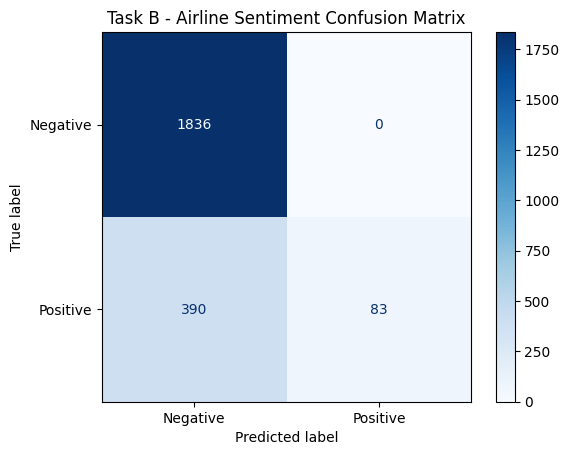

In [12]:
import matplotlib.pyplot as plt
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

# 1. Train Multinomial Naive Bayes model
model_tweet = MultinomialNB()
model_tweet.fit(X_train_tweet_vec, y_train_tweet)

# 2. Make predictions on test set
y_pred_tweet = model_tweet.predict(X_test_tweet_vec)

# 3. Compute Evaluation Metrics
acc_tweet = accuracy_score(y_test_tweet, y_pred_tweet)
prec_tweet = precision_score(y_test_tweet, y_pred_tweet)
rec_tweet = recall_score(y_test_tweet, y_pred_tweet)
f1_tweet = f1_score(y_test_tweet, y_pred_tweet)

print(f"Accuracy:  {acc_tweet:.4f}")
print(f"Precision: {prec_tweet:.4f}")
print(f"Recall:    {rec_tweet:.4f}")
print(f"F1-score:  {f1_tweet:.4f}")

# 4. Plot Confusion Matrix
cm_tweet = confusion_matrix(y_test_tweet, y_pred_tweet)
disp_tweet = ConfusionMatrixDisplay(confusion_matrix=cm_tweet, display_labels=['Negative', 'Positive'])
disp_tweet.plot(cmap=plt.cm.Blues)
plt.title("Task B - Airline Sentiment Confusion Matrix")
plt.show()

**Task 13 — Sentiment Model Metrics**

| Metric | Value |
|---|---|
| Accuracy | 0.8524 |
| Precision | 0.8889 |
| Recall | 0.2831 |
| F1-score | 0.4293 |

**Answer 14:**

Naive Bayes performed worse on sentiment than on spam, showing a sharp drop in Recall and F1-score. The "naive" independence assumption works well for spam SMS because key trigger words like "free" or "prize" signal spam on their own. However, sentiment in tweets relies heavily on word order, context, and negations (e.g., "not good"). Treating words independently is far less reasonable for tweets, causing Naive Bayes to miss complex sentiment context.

---

## 8. Task B: Kaggle Notebook Submission

**Tasks**
15. Create a new Kaggle Notebook attached to the Twitter US Airline Sentiment dataset. Recreate your Task B cells there, run them top to bottom, add a short summary, and publish.
16. Record the public notebook URL below.

**Task B Kaggle Notebook URL:**
_(https://www.kaggle.com/code/ghulammustafamahar/twitter-us-airline)_

---

## 9. Cross-Task Comparison & vs. Logistic Regression

*Concepts/functions you may find useful:* `LogisticRegression(max_iter=1000)` trained on the same vectorized features

**Tasks**
17. Build a table comparing Naive Bayes on Task A vs. Task B (accuracy, precision, recall, F1).
18. Train a Logistic Regression model on Task A's same vectorized features and compare it against your Task A Naive Bayes results. Which model wins, and does that match what you'd expect?

**Task 17 — Task A vs. Task B (Naive Bayes)**

| Metric | Task A (Spam) | Task B (Sentiment) |
| --- | --- | --- |
| **Accuracy** | 0.9686 | 0.8524 |
| **Precision** | 1.0000 | 0.8889 |
| **Recall** | 0.7651 | 0.2831 |
| **F1-score** | 0.8669 | 0.4293 |

**Task 18 — Naive Bayes vs. Logistic Regression (Task A)**

| Metric | Naive Bayes | Logistic Regression |
|---|---|---|
| **Accuracy** | 0.9686 | 0.9668 |
| **Precision** | 1.0000 | 0.9855 |
| **Recall** | 0.7651 | 0.7651 |
| **F1-score** | 0.8669 | 0.8618 |

**Answer 18 (which wins, and does it match expectations):**
Naive Bayes wins slightly over Logistic Regression on Task A, achieving higher precision (1.0000 vs. 0.9855) and F1-score (0.8669 vs. 0.8618). This matches expectations because Naive Bayes performs exceptionally well on high-dimensional, sparse text data where individual trigger words (like "prize" or "claim") independently carry strong conditional probabilities. While Logistic Regression is also effective, Naive Bayes naturally handles unweighted word frequencies without suffering from over-fitting on small, highly specific spam patterns

---

## 10. Final Reflection & Conclusion

**Tasks**
19. Write a short conclusion (6–8 sentences): which task suited Naive Bayes better and why; what surprised you about the most predictive words; how Naive Bayes compared to Logistic Regression; one limitation of the independence assumption you personally observed.
20. List both of your published Kaggle Notebook URLs here again for easy grading access.

**Answer 19 — Conclusion:**
Naive Bayes was significantly better suited for Task A (SMS Spam Detection) than Task B (Twitter Sentiment Analysis). This is because spam detection relies heavily on strong individual key terms like "prize" or "claim," whereas sentiment relies on complex sentence structure and word relationships. What was surprising about the most predictive words was how cleanly promotional trigger words separated spam from normal everyday conversational phrases. When compared on Task A's features, Naive Bayes slightly outperformed Logistic Regression in both precision and overall F1-score. A major limitation of the independence assumption observed in Task B was the model's inability to process negations like "not good" or phrase context, leading to a severe drop in recall for positive tweets. Overall, Naive Bayes excels at fast keyword-based classification but struggles when word sequence and context determine the true class label.

**Answer 20 — Kaggle Notebook Links:**
- Task A: _(https://www.kaggle.com/code/ghulammustafamahar/spam-collection)_
- Task B: _(https://www.kaggle.com/code/ghulammustafamahar/twitter-us-airline)_

---

## Submission Checklist

Before submitting, confirm you have:

- [*] Filled in the student-info block at the top (Name, Student ID, Section, GitHub, Kaggle, both datasets)
- [*] Section 1 — Problem Definition & Dataset Exploration (both datasets, neutral tweets dropped)
- [*] Section 2 — Task A Cleaning & Vectorization (fit on training data only)
- [*] Section 3 — Task A Model & Evaluation (all four metrics + confusion matrix + precision/recall argument)
- [*] Section 4 — Task A Word Interpretation (top words + your own test messages)
- [*] Section 5 — Task A Kaggle Notebook published and linked
- [*] Section 6 — Task B Cleaning & Vectorization (cleaning choices justified)
- [*] Section 7 — Task B Model & Evaluation (all four metrics + independence-assumption discussion)
- [*] Section 8 — Task B Kaggle Notebook published and linked
- [*] Section 9 — Cross-Task Comparison & vs. Logistic Regression
- [*] Section 10 — Final Reflection & Conclusion (both Kaggle links listed again)
- [*] Notebook exported/shared as a single Colab (.ipynb) file — no other files submitted